In [46]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [47]:
img = cv.imread(r'img.jpg', cv.IMREAD_GRAYSCALE)
img.shape

(554, 554)

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

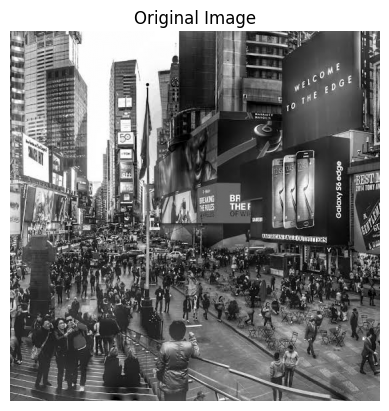

In [48]:
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

In [49]:
# first order derivative filters to find edges
def sobel_filter(image, ksize =3):
    k = ksize // 2
    
    # Create Sobel kernels
    x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
    
    # padding the image to handle borders
    padded = np.pad( image, 1, mode='constant')
    
    out_h, out_w = image.shape
    filtered_x = np.zeros((out_h, out_w), dtype=np.float32)
    filtered_y = np.zeros((out_h, out_w), dtype=np.float32)
    output = np.zeros((out_h, out_w), dtype=np.float32)
    # Convolution
    for i in range(out_h):
        for j in range(out_w):
            window = padded[i:i + ksize, j:j + ksize]
            sum_x = np.sum(window * x)
            sum_y = np.sum(window * y)
            filtered_x[i, j] = sum_x
            filtered_y[i, j] = sum_y
            output[i][j] = np.sqrt(sum_x**2 + sum_y**2)
            
    return np.clip(filtered_x, 0, 255).astype(np.uint8), np.clip(filtered_y, 0, 255).astype(np.uint8), np.clip(output, 0, 255).astype(np.uint8)

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

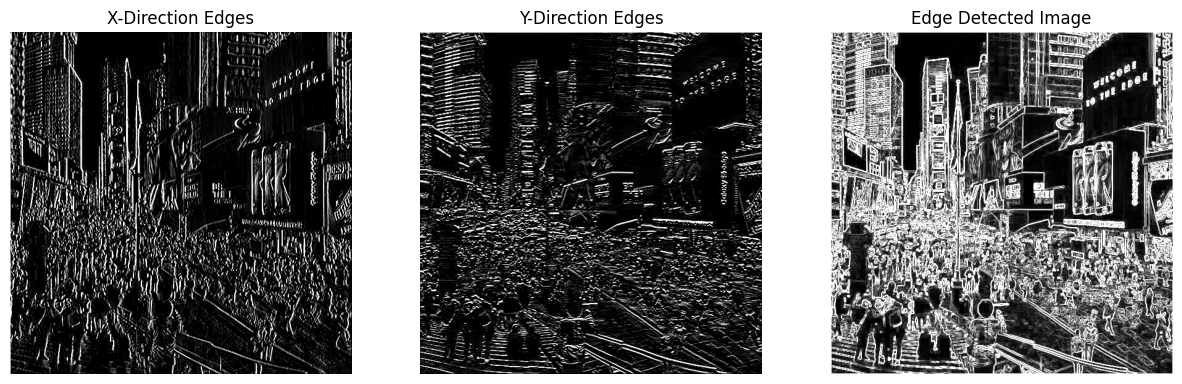

In [50]:
edge_x, edge_y, edge_image = sobel_filter(img, ksize=3)
plt.figure(figsize=(15,5))

plt.subplot(1, 3, 1)
plt.imshow(edge_x, cmap='gray')
plt.title('X-Direction Edges')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edge_y, cmap='gray')
plt.title('Y-Direction Edges')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(edge_image, cmap='gray')
plt.title('Edge Detected Image')
plt.axis('off')